# 01 — From DICOM to radiomic features

> **Dataset:** these results come from the **public TCIA Soft-tissue-Sarcoma** collection (51 patients), *not* from
> the STEREOSARC / Centre François Baclesse patients. Download and citation:
> https://www.cancerimagingarchive.net/collection/soft-tissue-sarcoma/ (doi:10.7937/K9/TCIA.2015.7GO2GSKS, CC BY 3.0).
> See the [README](../README.md#dataset-used-here-tcia-soft-tissue-sarcoma) for how to download it with `scripts/download_sts.py`.

**About the data:** TCIA *Soft-tissue-Sarcoma* (Vallières et al., 2015). 51 patients with sarcoma of the extremities,
FDG-PET/CT + MRI, and tumour contours as RTSTRUCT. We use the **CT** and the **`RTstruct_CT`** contours.

This notebook walks through the first steps of the pipeline on one patient:

1. **Import:** read the CT series and turn the RTSTRUCT contours into a voxel mask
2. **Look at the data:** orthogonal views, Hounsfield units, display windows
3. **Standardise:** why and how we resample to isotropic voxels
4. **Extract:** compute the PyRadiomics features and see what they mean
5. **Run it for every downloaded patient:** a first feature table (CSV)

For interactive browsing (slice slider, windows, ROI toggles), run the Streamlit viewer:
```
.venv/bin/streamlit run app/viewer.py
```

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import SimpleITK as sitk

from src.io_dicom import list_patients, load_patient
from src.preprocessing import WINDOWS, window, crop_to_mask, resample
from src.extraction import get_extractor, extract, features_to_frame

plt.rcParams["figure.dpi"] = 110
patients = list_patients()
patients

['STS_001',
 'STS_002',
 'STS_003',
 'STS_004',
 'STS_005',
 'STS_006',
 'STS_007',
 'STS_008',
 'STS_009',
 'STS_010',
 'STS_011',
 'STS_012',
 'STS_013',
 'STS_014',
 'STS_015',
 'STS_016',
 'STS_017',
 'STS_018',
 'STS_019',
 'STS_020',
 'STS_021',
 'STS_022',
 'STS_023',
 'STS_024',
 'STS_025',
 'STS_026',
 'STS_027',
 'STS_028',
 'STS_029',
 'STS_030',
 'STS_031',
 'STS_032',
 'STS_033',
 'STS_034',
 'STS_035',
 'STS_036',
 'STS_037',
 'STS_038',
 'STS_039',
 'STS_040',
 'STS_041',
 'STS_042',
 'STS_043',
 'STS_044',
 'STS_045',
 'STS_046',
 'STS_047',
 'STS_048',
 'STS_049',
 'STS_050',
 'STS_051']

**What the output shows:** the list of patients found in `data/raw/STS/`, i.e. the folders that contain a CT series.
`list_patients()` only scans the folder names: nothing is loaded yet. If the list is empty, the data has not been
downloaded (`scripts/download_sts.py`).

## 1. Import

A CT series is a folder of DICOM files, **one per slice**. SimpleITK (via GDCM) sorts them along the slice axis
and stacks them into a 3D volume that carries its **geometry**: origin (mm), voxel spacing (mm) and orientation.

The **RTSTRUCT** does not store voxels. It stores **polygons** (one per contoured slice) in patient coordinates (mm).
`rt-utils` rasterises them onto the CT grid to give a binary mask with the same geometry as the image.

In [2]:
PID = "STS_008"
ct, masks = load_patient(PID)

print("Size (x, y, z) :", ct.GetSize())
print("Spacing (mm)   :", tuple(round(s, 3) for s in ct.GetSpacing()))
print("Origin (mm)    :", tuple(round(o, 1) for o in ct.GetOrigin()))
print("ROIs           :", list(masks))

ct_arr = sitk.GetArrayFromImage(ct)  # numpy order is (z, y, x)!
mask = masks["GTV_Mass"]
m_arr = sitk.GetArrayFromImage(mask).astype(bool)
print("Array shape (z, y, x):", ct_arr.shape, "| tumour voxels:", m_arr.sum())

Size (x, y, z) : (512, 512, 267)
Spacing (mm)   : (0.977, 0.977, 3.27)
Origin (mm)    : (-250.0, -250.0, -864.8)
ROIs           : ['GTV_Mass']
Array shape (z, y, x): (267, 512, 512) | tumour voxels: 9007


**What the output shows:**
- **Size** `(512, 512, 267)`: 512 × 512 pixels per slice, 267 slices.
- **Spacing**: each voxel is 0.98 × 0.98 mm in the slice and **3.27 mm** between slices. The voxels are not cubes,
  which is why section 3 resamples them.
- **Origin**: the position (mm, in the scanner coordinate system) of the first voxel. Image and mask must share
  origin, spacing and orientation, otherwise the contour would land in the wrong place.
- **ROIs**: the contours stored in the RTSTRUCT. All patients have `GTV_Mass` (the tumour); 32 also have `GTV_Edema`
  (tumour + surrounding edema).
- **tumour voxels**: number of voxels inside the mask. Multiplied by the voxel volume (0.98 × 0.98 × 3.27 ≈ 3.1 mm³)
  it gives the tumour volume (≈ 28 cm³ for this patient).

⚠️ **Axis order:** SimpleITK uses `(x, y, z)`, while the numpy array from `GetArrayFromImage` is `(z, y, x)`.
This is the most common source of bugs when going back and forth between the two.

## 2. Looking at the data

### Orthogonal views through the tumour centre
The voxels are **not cubic** (≈0.98 × 0.98 × 3.27 mm), so the coronal and sagittal views need an aspect
correction, otherwise they look squashed.

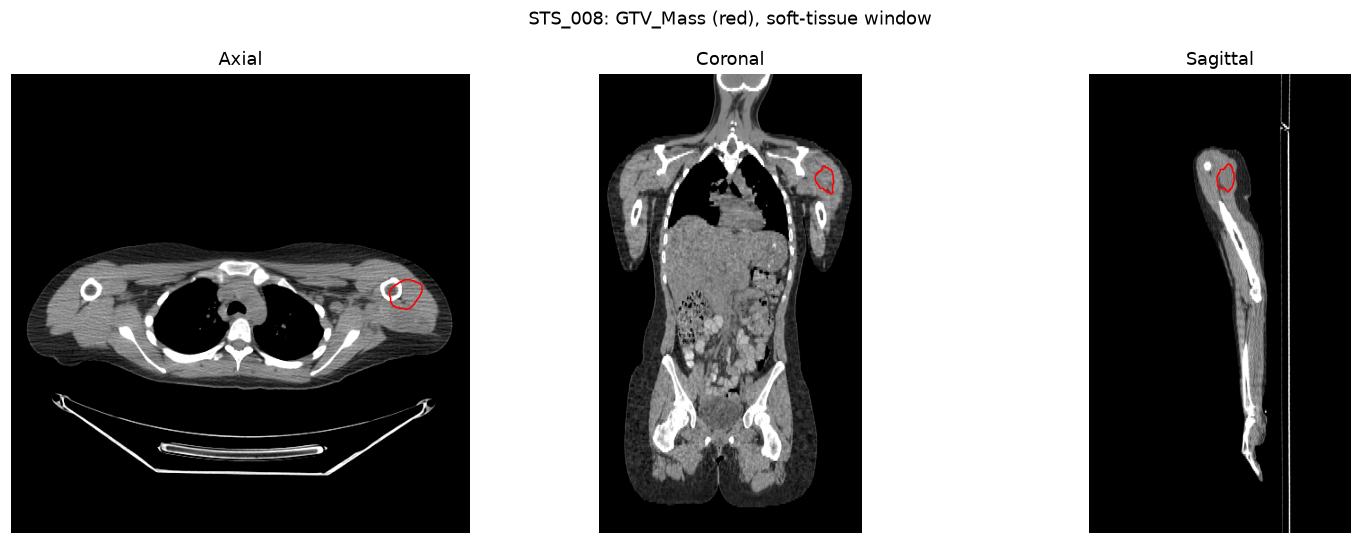

In [3]:
zc, yc, xc = [int(np.mean(i)) for i in np.nonzero(m_arr)]
sx, sy, sz = ct.GetSpacing()
c, w = WINDOWS["soft tissue"]

views = [
    ("Axial", ct_arr[zc], m_arr[zc], 1.0),
    ("Coronal", ct_arr[:, yc, :], m_arr[:, yc, :], sz / sx),
    ("Sagittal", ct_arr[:, :, xc], m_arr[:, :, xc], sz / sy),
]
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
for ax, (title, img, msk, aspect) in zip(axes, views):
    origin = "upper" if title == "Axial" else "lower"   # head at the top
    ax.imshow(window(img, c, w), cmap="gray", aspect=aspect, origin=origin)
    ax.contour(msk, levels=[0.5], colors="red", linewidths=1, origin=origin)
    ax.set_title(f"{title}"); ax.axis("off")
fig.suptitle(f"{PID}: GTV_Mass (red), soft-tissue window")
plt.tight_layout()

**What the output shows:** three perpendicular cuts through the centre of the tumour: **axial** (as if looking from
the feet), **coronal** (from the front) and **sagittal** (from the side). The red line is the expert contour
rasterised on the CT grid. If the red line follows the visible mass in all three views, steps 1 (reading) and the
axis conversions are correct. This is the first visual QC check.

### Hounsfield units (HU) and display windows
CT values are calibrated in **HU**: air ≈ −1000, fat ≈ −100, water = 0, soft tissue/muscle ≈ +40, bone > +400.
A screen shows only ~256 grey levels, so we pick a **window** (centre, width) to display one range of HU.

**Important:** the window is **only for display**. Radiomic features are always computed on the raw HU values.

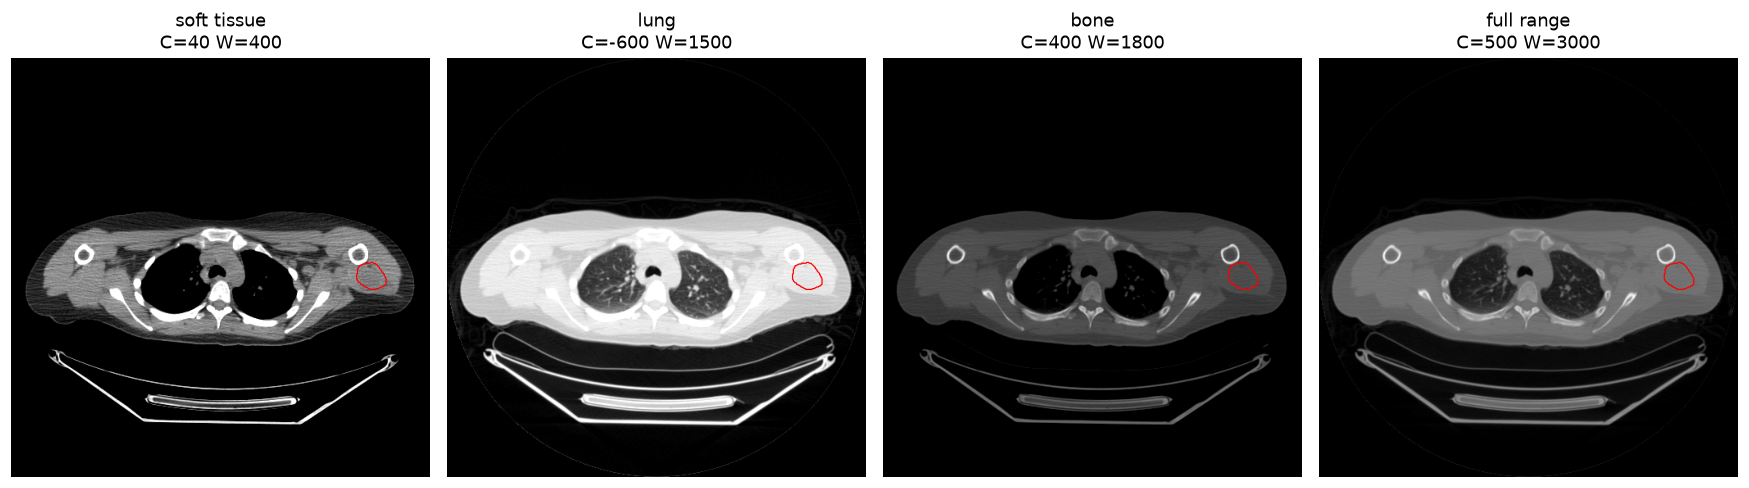

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4.3))
for ax, (name, (c_, w_)) in zip(axes, WINDOWS.items()):
    ax.imshow(window(ct_arr[zc], c_, w_), cmap="gray")
    ax.contour(m_arr[zc], levels=[0.5], colors="red", linewidths=0.8)
    ax.set_title(f"{name}\nC={c_} W={w_}"); ax.axis("off")
plt.tight_layout()

**What the output shows:** the **same slice** with four display windows. Only the mapping from HU to grey changes:
the soft-tissue window makes the tumour and muscle readable, the lung window shows air-filled structures, the
bone window shows the skeleton, the full range shows everything but with little contrast. The data underneath is
identical in the four images.

Tumour HU: mean=39.4  sd=26.7


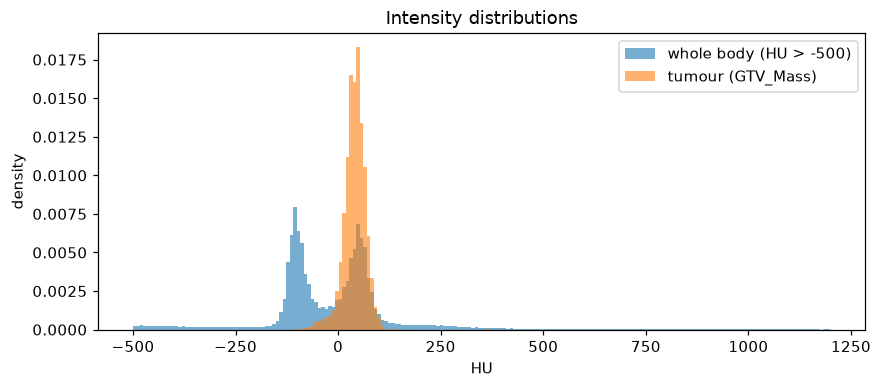

In [5]:
body = ct_arr > -500
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.hist(ct_arr[body].ravel(), bins=200, range=(-500, 1200), density=True, alpha=.6, label="whole body (HU > -500)")
ax.hist(ct_arr[m_arr].ravel(), bins=200, range=(-500, 1200), density=True, alpha=.6, label="tumour (GTV_Mass)")
ax.set_xlabel("HU"); ax.set_ylabel("density"); ax.legend(); ax.set_title("Intensity distributions")
print(f"Tumour HU: mean={ct_arr[m_arr].mean():.1f}  sd={ct_arr[m_arr].std():.1f}")

**What the output shows:** two normalised histograms of HU values. The **whole-body** one has peaks for fat (≈ −100),
soft tissue/muscle (≈ +40) and a long tail for bone. The **tumour** one sits in the soft-tissue range. Its mean and
spread (printed) are exactly what the `firstorder` features will quantify. The width of the tumour histogram is a
first, crude measure of heterogeneity.

## 3. Standardisation: isotropic resampling

Texture features compare each voxel with its **neighbours**. With 0.98 × 0.98 × 3.27 mm voxels, a "neighbour"
is 1 mm away in-plane but 3.3 mm away across slices, so the features would mix in the scanner geometry.
Scans with different slice thicknesses would also not be comparable.

Standard practice (IBSI) is to **resample to isotropic voxels**, here 1 × 1 × 1 mm:
- **image:** B-spline interpolation (smooth)
- **mask:** nearest neighbour (stays binary)

To save memory we first **crop** around the tumour with a 10 mm margin. PyRadiomics does the same internally.

cropped    size=(59, 55, 27)  spacing=(0.98, 0.98, 3.27)
resampled  size=(58, 54, 88)  spacing=(1.0, 1.0, 1.0)


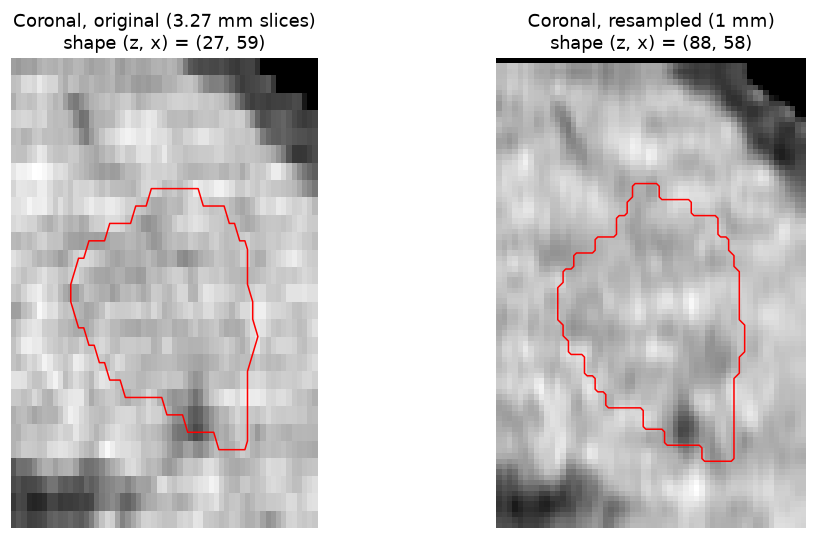

In [6]:
crop_img, crop_msk = crop_to_mask(ct, mask, pad_mm=10)
iso_img, iso_msk = resample(crop_img), resample(crop_msk, is_mask=True)

for name, im in [("cropped", crop_img), ("resampled", iso_img)]:
    print(f"{name:10s} size={im.GetSize()}  spacing={tuple(round(s, 2) for s in im.GetSpacing())}")

a0, m0 = sitk.GetArrayFromImage(crop_img), sitk.GetArrayFromImage(crop_msk)
a1, m1 = sitk.GetArrayFromImage(iso_img), sitk.GetArrayFromImage(iso_msk)
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, (t, a, m, asp) in zip(axes, [("original (3.27 mm slices)", a0, m0, sz / sx), ("resampled (1 mm)", a1, m1, 1.0)]):
    y = a.shape[1] // 2
    ax.imshow(window(a[:, y, :], c, w), cmap="gray", origin="lower", interpolation="nearest", aspect=asp)
    ax.contour(m[:, y, :], levels=[0.5], colors="red", linewidths=1, origin="lower")
    ax.set_title(f"Coronal, {t}\nshape (z, x) = {a[:, y, :].shape}"); ax.axis("off")
plt.tight_layout()

**What the output shows:**
- The printed sizes: after cropping, the region is 59 × 55 × 27 voxels; after resampling to 1 mm it becomes
  58 × 54 × 88. The physical extent is the same, only the grid changes (27 slices of 3.27 mm ≈ 88 slices of 1 mm).
- The images: the same coronal cut before and after resampling.

Both panels are drawn at the same physical scale. On the left each row is a 3.27 mm thick slice, so the image and the contour look like stacked bricks.
On the right the grid is cubic. Interpolation does **not** add information, but it puts every scan
on the **same grid**, so the features can be compared.

## 4. Feature extraction with PyRadiomics

The settings live in `config/pyradiomics_params.yaml` (bin width 25 HU, 1 mm resampling, HU range [−150, 400] for
the intensity mask). Keeping them in a file makes the extraction **reproducible**.

| Class | # | What it measures | Example |
|---|---|---|---|
| `shape` | 14 | 3D geometry of the ROI (independent of intensities) | `MeshVolume`, `Sphericity`, `Elongation` |
| `firstorder` | 18 | Histogram of HU values in the ROI | `Mean`, `Entropy`, `Skewness`, `90Percentile` |
| `glcm` | 24 | Grey Level Co-occurrence: how often pairs of neighbouring voxels have values (i, j) | `Contrast`, `Correlation`, `JointEntropy` |
| `glrlm` | 16 | Grey Level Run Length: lengths of runs of identical grey level along a direction | `LongRunEmphasis` |
| `glszm` | 16 | Grey Level Size Zone: sizes of connected zones of identical grey level | `ZonePercentage`, `LargeAreaEmphasis` |
| `gldm` | 14 | Grey Level Dependence: how many neighbours depend on (are similar to) each voxel | `DependenceEntropy` |
| `ngtdm` | 5 | Neighbouring Grey Tone Difference: difference between a voxel and its neighbourhood | `Coarseness`, `Busyness` |

Texture classes (glcm…ngtdm) put numbers on **heterogeneity**, which the eye can see only roughly.

In [7]:
extractor = get_extractor()
feats = extract(ct, mask, extractor)
df = features_to_frame(feats)
print(len(df), "features")
df.groupby("class").size()

107 features


class
firstorder    18
glcm          24
gldm          14
glrlm         16
glszm         16
ngtdm          5
shape         14
dtype: int64

**What the output shows:** PyRadiomics returns **107 features** for one (image, mask) pair, split into the 7 classes
of the table above. This is the "radiomic signature" of the tumour: one vector of 107 numbers. The `diagnostics_*`
entries (versions, settings, image hashes) are removed by `extract()`; they are useful for traceability but are not
features.

In [8]:
show = ["MeshVolume", "Sphericity", "Elongation", "Mean", "Entropy", "Skewness",
        "Contrast", "JointEntropy", "ZonePercentage", "Coarseness", "Busyness"]
df[df.feature.isin(show)].sort_values("class").reset_index(drop=True)

,class,feature,value
0,firstorder,Entropy,2.033079
1,firstorder,Mean,38.889573
2,firstorder,Skewness,-0.702734
3,glcm,Contrast,1.008826
4,glcm,JointEntropy,3.712452
5,glszm,ZonePercentage,0.012233
6,ngtdm,Busyness,15.906485
7,ngtdm,Coarseness,0.000296
8,ngtdm,Contrast,0.003704
9,shape,Elongation,0.674046


**What the output shows:** a few features with their values for this patient, e.g.:
- `MeshVolume` ≈ 27 400 mm³ (≈ 27 cm³), `Sphericity` 0.72 (1 = perfect sphere), `Elongation` 0.67;
- `Mean` ≈ 39 HU (soft tissue), `Skewness` < 0 (a tail towards low HU, e.g. a fatty or necrotic part);
- texture features (`Contrast`, `JointEntropy`, `Coarseness`, …) have **no physical unit** and only make sense when
  compared between patients or between scans, which is the point of the next notebook.

### Intuition: what "texture" captures
We compare the GLCM `JointEntropy` of the real tumour with two synthetic versions:
a **flat** one (every voxel = mean HU) and a **noisier** one (extra Gaussian noise).
Same shape, different heterogeneity → the texture features change, the shape features do not.

In [9]:
rng = np.random.default_rng(0)
variants = {"real": a1.astype(np.float32)}
variants["flat"] = np.where(m1 > 0, a1[m1 > 0].mean(), a1).astype(np.float32)
variants["noisier"] = (a1 + rng.normal(0, 40, a1.shape) * (m1 > 0)).astype(np.float32)

rows = []
for name, arr in variants.items():
    im = sitk.GetImageFromArray(arr); im.CopyInformation(iso_img)
    f = extract(im, iso_msk, extractor)
    rows.append({"variant": name, **{k.split("_", 2)[2]: f[k] for k in [
        "original_shape_MeshVolume", "original_firstorder_Variance",
        "original_glcm_JointEntropy", "original_ngtdm_Coarseness"]}})
pd.DataFrame(rows).set_index("variant").round(3)

,MeshVolume,Variance,JointEntropy,Coarseness
variant,,,,
real,27580.667,639.261,3.700,0.0
flat,27580.667,0.000,-0.000,1000000.0
noisier,27580.667,2258.181,5.938,0.0


**What the output shows:**
- `MeshVolume` is **identical** in the three rows: shape features ignore intensities.
- `flat` (every voxel equal): variance 0, joint entropy 0 and the maximum coarseness value (PyRadiomics returns 10⁶
  when there is no texture at all). This is the "no heterogeneity" reference.
- `noisier`: variance and joint entropy increase, coarseness stays ≈ 0. The features move in the expected direction,
  which is a sanity check that the extraction measures what we think it measures.

## 5. Several patients → first feature table

Same code in a loop, here on the **first 8 patients** to keep the notebook fast (≈ 20 s per patient).
The result is the tabular format the pipeline is meant to produce: **one row per (patient, ROI)**, one column per
feature. It is saved to `outputs/features_demo.csv`.

The full cohort (51 patients, plus the robustness conditions) is extracted by `scripts/extract_cohort.py`
and analysed in notebook 02.

In [10]:
rows = []
for pid in patients[:8]:
    ct_p, masks_p = load_patient(pid)
    f = extract(ct_p, masks_p["GTV_Mass"], extractor)
    rows.append({"PatientID": pid, "ROI": "GTV_Mass", **f})
    print(pid, "ok")

features = pd.DataFrame(rows)
out = ROOT / "outputs" / "features_demo.csv"
out.parent.mkdir(exist_ok=True)
features.to_csv(out, index=False)
print(features.shape, "->", out.relative_to(ROOT))
features.iloc[:, :8]

STS_001 ok


STS_002 ok


STS_003 ok


STS_004 ok


STS_005 ok


STS_006 ok


STS_007 ok


STS_008 ok
(8, 109) -> outputs/features_demo.csv


,PatientID,ROI,original_shape_Elongation,original_shape_Flatness,original_shape_LeastAxisLength,original_shape_MajorAxisLength,original_shape_Maximum2DDiameterColumn,original_shape_Maximum2DDiameterRow
0,STS_001,GTV_Mass,0.766878,0.645594,65.325936,101.187282,108.466585,109.635761
1,STS_002,GTV_Mass,0.892724,0.680213,34.200904,50.279666,55.731499,53.600373
2,STS_003,GTV_Mass,0.719076,0.691369,42.166185,60.989375,63.560994,72.718636
3,STS_004,GTV_Mass,0.529053,0.440693,54.111022,122.786190,177.290722,159.201131
4,STS_005,GTV_Mass,0.604636,0.494162,69.359457,140.357860,161.966046,144.367586
5,STS_006,GTV_Mass,0.564818,0.370679,44.962197,121.296755,156.016025,151.198545
6,STS_007,GTV_Mass,0.506183,0.422851,67.163929,158.836036,147.186956,122.286549
7,STS_008,GTV_Mass,0.674046,0.569784,27.107138,47.574381,65.741920,53.338541


**What the output shows:** the shape of the table (8 rows × 109 columns = PatientID + ROI + 107 features) and its
first columns. This CSV is deliverable 4 of the project in miniature ("structured database of radiomic
features").

Text(0.5, 1.0, 'Radiomic features per patient')

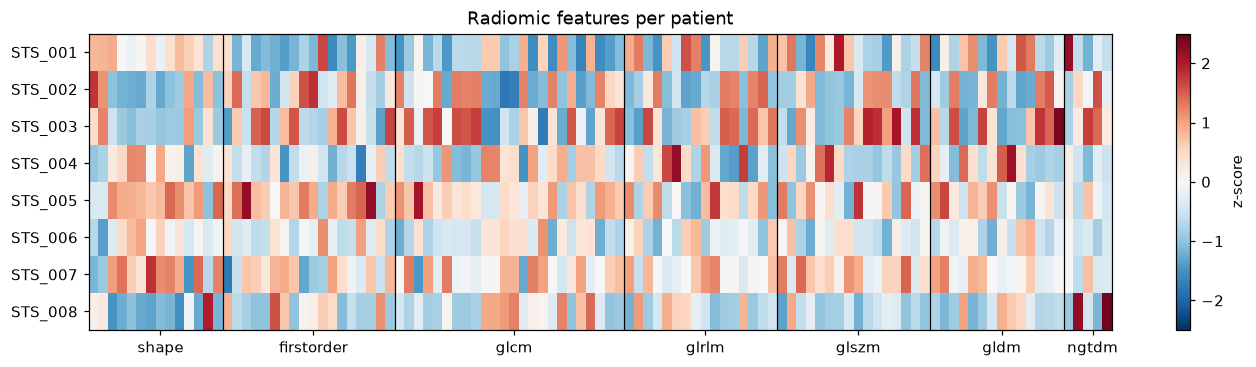

In [11]:
# z-scored features (rows = patients). Columns are grouped by class.
X = features.set_index("PatientID").drop(columns="ROI")
Z = (X - X.mean()) / X.std().replace(0, 1)
fig, ax = plt.subplots(figsize=(15, 3.5))
im = ax.imshow(Z.values, aspect="auto", cmap="RdBu_r", vmin=-2.5, vmax=2.5)
ax.set_yticks(range(len(Z)), Z.index)
classes = [c.split("_")[1] for c in Z.columns]
bounds = [i for i in range(1, len(classes)) if classes[i] != classes[i - 1]]
for b in bounds: ax.axvline(b - .5, color="k", lw=.8)
ax.set_xticks([(a + b) / 2 for a, b in zip([0] + bounds, bounds + [len(classes)])],
              [classes[i] for i in [0] + bounds])
plt.colorbar(im, label="z-score"); ax.set_title("Radiomic features per patient")

**What the output shows:** each row is a patient, each column a feature, grouped by class (black lines). Values are
**z-scores** (how many standard deviations above/below the mean of these patients): red = high, blue = low.
Features have very different units, so z-scoring is needed to put them on one picture. Columns that look alike
across rows are features that carry the same information. Rows that are red almost everywhere in `shape` are
the large tumours.

In [12]:
# Many features are strongly correlated with each other, often with volume.
# That redundancy is why feature selection comes before any model.
corr = X.corr(method="spearman").abs()
vol_corr = corr["original_shape_MeshVolume"].drop("original_shape_MeshVolume")
print(f"{(vol_corr > 0.8).sum()} / {len(vol_corr)} features have |rho| > 0.8 with tumour volume")
upper = corr.where(np.triu(np.ones(corr.shape, bool), 1))
print(f"{(upper > 0.9).sum().sum()} feature pairs with |rho| > 0.9")

17 / 106 features have |rho| > 0.8 with tumour volume
580 feature pairs with |rho| > 0.9


**What the output shows:** how many features are strongly correlated (Spearman |ρ| > 0.8) with tumour volume, and
how many feature pairs are almost duplicates (|ρ| > 0.9). Many "texture" features partly measure size. This is
the motivation for notebook 02: remove unstable and redundant features before any prediction, and always compare
a radiomic model with **volume alone**.

⚠️ With only a few patients these correlations are very noisy. The point is to show the method, not a result.

## Next: notebook 02
`02_robustness_and_model.ipynb` takes the features of the **51 patients**, computed under several perturbations
(contour ±1 mm, bin width 15/25/40 HU), and:
- measures the **robustness** of each feature (ICC) and keeps the stable ones;
- removes **redundant** features;
- tests whether they predict **lung metastases**, with a cross-validated model compared with tumour volume alone.